# 04 · Calendar-aging fit (Stage 1, full factorial)

First parametric fit for the thesis. Fits a calendar-aging model to the Stage-1 full-factorial (FF) calendar arm and compares two uncertainty estimates for its parameters: Fisher (Gauss–Newton) standard errors and a cell-level cluster bootstrap. This is the first C2 data point.

**Model** (`src/calendar_model.py`):

$$Q_{\mathrm{rel}}(t) = 1 - k(T,\mathrm{SoC})\,(t^{z} - t_0^{z}), \qquad \log k = \log k_{\mathrm{ref}} - \frac{E_a}{R}\Big(\frac{1}{T}-\frac{1}{T_{\mathrm{ref}}}\Big) + c_{\mathrm{SoC}}(\mathrm{SoC}-0.5)$$

$Q_{\mathrm{rel}}$ is normalized to each cell's first regular check-up at $t_0$; $T_{\mathrm{ref}} = 23\,^{\circ}$C; $t$ in years.

**Data scope.** Of the 66 Stage-1 calendar cells, 33 have only entry and end tests (no regular check-ups) and are excluded here; the fit uses the 33 cells with regular CU/exCU check-ups (3 per condition, 11 conditions).

In [1]:
# Load Stage-1 FF calendar check-ups
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
from calendar_model import load_calendar

PARQUET = "../data/processed/capacity_rpt.parquet"
d = load_calendar(PARQUET, stage=1, sampling="FF")
print(f"rows: {len(d)} | cells: {d['cell_id'].nunique()} | conditions: {d['cond'].nunique()}")
d.groupby("cond").agg(cells=("cell_id", "nunique"), checkups=("Q_rel", "size"),
                      max_days=("days", "max"), min_Q_rel=("Q_rel", "min"))

rows: 165 | cells: 33 | conditions: 11


,cells,checkups,max_days,min_Q_rel
cond,,,,
10C/0.05,3,18,349.0,0.992336
10C/0.50,3,18,349.0,0.987721
10C/1.00,3,18,341.0,0.978936
23C/0.05,3,12,285.0,0.994796
23C/0.50,3,12,285.0,0.987283
23C/1.00,3,12,285.0,0.979564
45C/0.05,3,15,304.0,0.991067
45C/0.20,3,15,306.0,0.983868
45C/0.50,3,15,306.0,0.963648


In [2]:
# Fit parametric model (4 parameters) and saturated model (free rate per condition, shared z)
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
from calendar_model import load_calendar, fit, predict_param, predict_saturated, PARAM_NAMES

d = load_calendar("../data/processed/capacity_rpt.parquet", stage=1, sampling="FF")
conds = sorted(d["cond"].unique())

fp = fit(predict_param, d, np.array([np.log(0.02), 30.0, 1.0, 0.6]))
fs = fit(predict_saturated, d, np.r_[np.full(len(conds), np.log(0.02)), 0.6], conds=conds)

se = np.sqrt(np.diag(fp["cov"]))
print(pd.DataFrame({"estimate": fp["theta"], "Fisher SE": se}, index=PARAM_NAMES).round(4))
print(f"\nresidual SD (parametric): {np.sqrt(fp['rss'] / (fp['n'] - fp['p'])):.5f}")
print(f"residual SD (saturated):  {np.sqrt(fs['rss'] / (fs['n'] - fs['p'])):.5f}")

# Lack-of-fit F-test: parametric (nested) vs saturated condition effects
from scipy import stats
df1, df2 = fs["p"] - fp["p"], fs["n"] - fs["p"]
F = ((fp["rss"] - fs["rss"]) / df1) / (fs["rss"] / df2)
print(f"lack-of-fit F({df1}, {df2}) = {F:.1f}, p = {stats.f.sf(F, df1, df2):.2e}")

           estimate  Fisher SE
log_k_ref   -3.8891     0.0417
Ea_kJ       24.8698     1.2458
c_soc        1.2533     0.0641
z            0.7896     0.0939

residual SD (parametric): 0.00378
residual SD (saturated):  0.00155


lack-of-fit F(8, 153) = 100.5, p = 5.87e-57


In [3]:
# Per-condition residual bias of the parametric model
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
from calendar_model import load_calendar, fit, predict_param

d = load_calendar("../data/processed/capacity_rpt.parquet", stage=1, sampling="FF")
fp = fit(predict_param, d, np.array([np.log(0.02), 30.0, 1.0, 0.6]))
d["resid"] = fp["resid"]                                    # predicted minus observed
(d.groupby("cond")["resid"].agg(["mean", "std", "size"]) * [100, 100, 1]).round(3).rename(
    columns={"mean": "mean resid (% Q0)", "std": "SD (% Q0)", "size": "n"})

,mean resid (% Q0),SD (% Q0),n
cond,,,
10C/0.05,0.078,0.117,18
10C/0.50,0.083,0.100,18
10C/1.00,0.170,0.098,18
23C/0.05,-0.347,0.228,12
23C/0.50,-0.059,0.046,12
23C/1.00,-0.232,0.238,12
45C/0.05,-0.403,0.250,15
45C/0.20,-0.172,0.117,15
45C/0.50,0.451,0.230,15


In [4]:
# Fisher vs cell-level cluster bootstrap standard errors (B = 1000)
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
from calendar_model import load_calendar, fit, predict_param, cluster_bootstrap, PARAM_NAMES

d = load_calendar("../data/processed/capacity_rpt.parquet", stage=1, sampling="FF")
fp = fit(predict_param, d, np.array([np.log(0.02), 30.0, 1.0, 0.6]))
draws = cluster_bootstrap(predict_param, d, fp["theta"], B=1000, seed=0)

se_fisher = np.sqrt(np.diag(fp["cov"]))
se_boot = draws.std(axis=0, ddof=1)
lo, hi = np.percentile(draws, [2.5, 97.5], axis=0)
tab = pd.DataFrame({"estimate": fp["theta"], "Fisher SE": se_fisher, "bootstrap SE": se_boot,
                    "ratio boot/Fisher": se_boot / se_fisher,
                    "Wald 95% lo": fp["theta"] - 1.96 * se_fisher, "Wald 95% hi": fp["theta"] + 1.96 * se_fisher,
                    "pct 95% lo": lo, "pct 95% hi": hi}, index=PARAM_NAMES)
np.save("../data/processed/calendar_s1_boot.npy", draws)
tab.round(4)

,estimate,Fisher SE,bootstrap SE,ratio boot/Fisher,Wald 95% lo,Wald 95% hi,pct 95% lo,pct 95% hi
log_k_ref,-3.8891,0.0417,0.0166,0.3973,-3.9709,-3.8074,-3.9240,-3.8587
Ea_kJ,24.8698,1.2458,0.4647,0.3730,22.4281,27.3115,23.9427,25.7926
c_soc,1.2533,0.0641,0.0249,0.3886,1.1275,1.3790,1.2032,1.3023
z,0.7896,0.0939,0.0195,0.2080,0.6056,0.9737,0.7523,0.8287


**Caveats for interpretation.**
- Fisher SEs assume independent, homoscedastic residuals and a correct model. Repeated check-ups on the same cell are correlated, and the lack-of-fit test above indicates the parametric SoC/temperature form is misspecified; the pooled residual variance therefore absorbs model discrepancy.
- The cluster bootstrap resamples only 3 cells per condition, so it has few distinct resamples and is biased low by roughly $\sqrt{(n-1)/n}$ per condition. Neither SE is a reliable benchmark on its own; this motivates the C2 simulation study, where the truth is known.

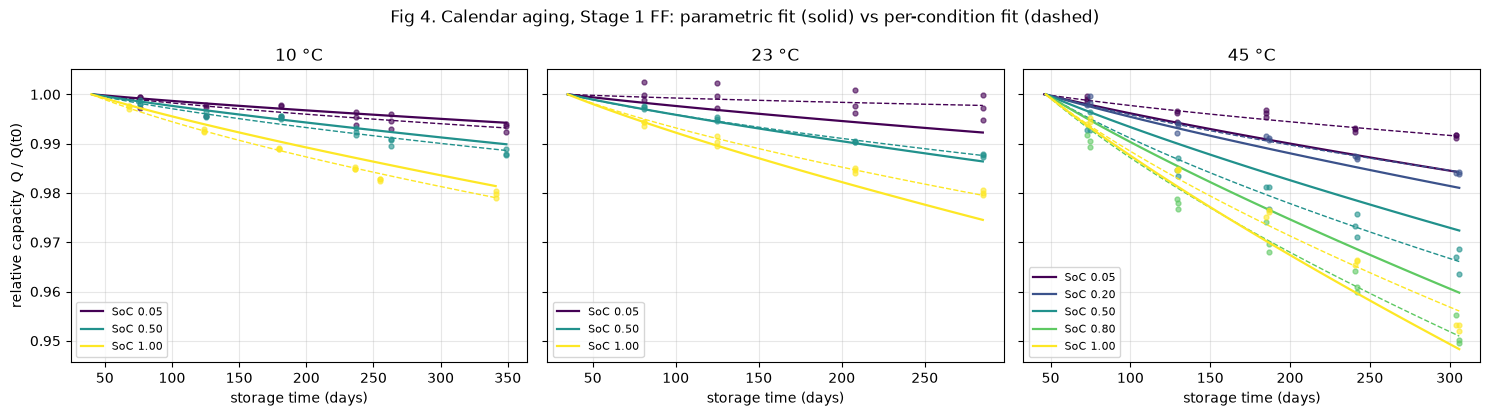

In [5]:
# Fig 4: Stage-1 calendar data with parametric (solid) and saturated (dashed) fits
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from calendar_model import load_calendar, fit, predict_param, predict_saturated

d = load_calendar("../data/processed/capacity_rpt.parquet", stage=1, sampling="FF")
conds = sorted(d["cond"].unique())
fp = fit(predict_param, d, np.array([np.log(0.02), 30.0, 1.0, 0.6]))
fs = fit(predict_saturated, d, np.r_[np.full(len(conds), np.log(0.02)), 0.6], conds=conds)

socs = sorted(d["soc"].unique())
cmap = plt.get_cmap("viridis")
colors = {s: cmap(i / (len(socs) - 1)) for i, s in enumerate(socs)}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, T in zip(axes, sorted(d["amb_temp_tp"].unique())):
    dT = d[d["amb_temp_tp"] == T]
    for s, g in dT.groupby("soc"):
        for _, cg in g.groupby("cell_id"):
            ax.plot(cg["days"], cg["Q_rel"], "o", ms=3.5, color=colors[s], alpha=0.6)
        t0 = g["t0"].median()
        grid = pd.DataFrame({"t": np.linspace(t0, g["t"].max(), 100)})
        grid = grid.assign(t0=t0, T_K=T + 273.15, soc=s, cond=g["cond"].iloc[0])
        ax.plot(grid["t"] * 365.25, predict_param(fp["theta"], grid), "-", color=colors[s], lw=1.6,
                label=f"SoC {s:.2f}")
        ax.plot(grid["t"] * 365.25, predict_saturated(fs["theta"], grid, conds), "--", color=colors[s], lw=1)
    ax.set_title(f"{T} °C")
    ax.set_xlabel("storage time (days)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="lower left")
axes[0].set_ylabel("relative capacity  Q / Q(t0)")
fig.suptitle("Fig 4. Calendar aging, Stage 1 FF: parametric fit (solid) vs per-condition fit (dashed)")
fig.tight_layout()
fig.savefig("../figs/fig4_calendar_fit.png", dpi=200, bbox_inches="tight")
plt.show()

## Per-SoC-level effects

The log-linear SoC term is replaced by a free additive effect $\delta_s$ on $\log k$ for each SoC level $s \in \{0.05, 0.2, 0.8, 1.0\}$ (SoC 0.5 is the baseline, $\delta = 0$):

$$\log k = \log k_{\mathrm{ref}} - \frac{E_a}{R}\Big(\frac{1}{T}-\frac{1}{T_{\mathrm{ref}}}\Big) + \delta_{s}$$

This has 7 parameters ($\log k_{\mathrm{ref}}$, $E_a$, four $\delta_s$, $z$) against 12 in the saturated model, so the lack-of-fit test has 5 numerator df. SoC 0.2 and 0.8 appear only at 45 °C, so their effects are identified through the additive (no temperature × SoC interaction) structure.

In [6]:
# Per-SoC-level fit vs saturated model: re-run lack-of-fit F-test
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
from scipy import stats
from calendar_model import *

d = load_calendar("../data/processed/capacity_rpt.parquet", stage=1, sampling="FF")
conds = sorted(d["cond"].unique())
lv = soc_levels(d)
names = soc_param_names(lv)
x0 = np.r_[np.log(0.02), 30.0, np.zeros(len(lv)), 0.6]

fl = fit(predict_soc_levels, d, x0, levels=lv)
fs = fit(predict_saturated, d, np.r_[np.full(len(conds), np.log(0.02)), 0.6], conds=conds)

print(pd.DataFrame({"estimate": fl["theta"], "Fisher SE": np.sqrt(np.diag(fl["cov"]))}, index=names).round(4))
print(f"\nresidual SD (per-SoC): {np.sqrt(fl['rss'] / (fl['n'] - fl['p'])):.5f}")
df1, df2 = fs["p"] - fl["p"], fs["n"] - fs["p"]
F = ((fl["rss"] - fs["rss"]) / df1) / (fs["rss"] / df2)
print(f"lack-of-fit F({df1}, {df2}) = {F:.1f}, p = {stats.f.sf(F, df1, df2):.2e}")

d["resid"] = fl["resid"]                                    # predicted minus observed
(d.groupby("cond")["resid"].agg(["mean", "std", "size"]) * [100, 100, 1]).round(3).rename(
    columns={"mean": "mean resid (% Q0)", "std": "SD (% Q0)", "size": "n"})

               estimate  Fisher SE
log_k_ref       -3.6726     0.0300
Ea_kJ           23.0960     0.7682
delta_soc0.05   -1.2659     0.0846
delta_soc0.20   -0.6986     0.0600
delta_soc0.80    0.4384     0.0300
delta_soc1.00    0.3411     0.0282
z                0.7385     0.0539

residual SD (per-SoC): 0.00220
lack-of-fit F(5, 153) = 33.0, p = 9.57e-23


,mean resid (% Q0),SD (% Q0),n
cond,,,
10C/0.05,0.199,0.140,18
10C/0.50,-0.072,0.088,18
10C/1.00,0.216,0.123,18
23C/0.05,-0.171,0.199,12
23C/0.50,-0.252,0.121,12
23C/1.00,-0.129,0.168,12
45C/0.05,-0.027,0.100,15
45C/0.20,-0.008,0.079,15
45C/0.50,0.182,0.205,15


## Cell-level random effect on $\log k$

Each cell $c$ gets its own rate shift: $\log k_c = \log k(T,\mathrm{SoC}) + b_c$, $b_c \sim N(0,\tau^2)$, with independent $N(0,\sigma^2)$ errors given $b_c$. The fit maximizes the marginal likelihood, integrating out $b_c$ by adaptive Gauss–Hermite quadrature (15 nodes centred at each cell's posterior mode; fade is multiplied by $e^{b_c}$; agrees with 60 nodes to 8 digits). Plain Gauss–Hermite on the prior scale is inadequate here because the data are much more informative about $b_c$ than the prior is. Fixed-effect SEs come from the inverse numerical Hessian at the ML estimate. This is ML, not REML, so $\sigma$ is not degrees-of-freedom corrected.

In [7]:
# Mixed-effects fit (cell random effect on log k); LRT for tau = 0
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
from scipy import stats
from calendar_model import *

d = load_calendar("../data/processed/capacity_rpt.parquet", stage=1, sampling="FF")
conds = sorted(d["cond"].unique())
lv = soc_levels(d)
names = soc_param_names(lv)
x0 = np.r_[np.log(0.02), 30.0, np.zeros(len(lv)), 0.6]

fl = fit(predict_soc_levels, d, x0, levels=lv)
mm = fit_mixed(predict_soc_levels, d, fl["theta"], levels=lv)

# Fixed-effects (tau = 0) ML log-likelihood from the least-squares fit
s2_ml = fl["rss"] / fl["n"]
ll0 = -0.5 * fl["n"] * (np.log(2 * np.pi * s2_ml) + 1)
lrt = 2 * (mm["loglik"] - ll0)
# tau = 0 is on the boundary, so the null distribution is a 50:50 mixture of chi2_0 and chi2_1
print(f"sigma = {mm['sigma']:.5f} (fixed-effects ML: {np.sqrt(s2_ml):.5f}) | tau = {mm['tau']:.4f}")
print(f"LRT tau=0: {lrt:.1f}, p = {0.5 * stats.chi2.sf(lrt, 1):.2e}")

pd.DataFrame({"estimate": mm["theta"], "mixed SE": mm["se"]}, index=names).round(4)

sigma = 0.00138 (fixed-effects ML: 0.00215) | tau = 0.2056
LRT tau=0: 59.1, p = 7.49e-15


,estimate,mixed SE
log_k_ref,-3.7406,0.0736
Ea_kJ,19.9035,2.2355
delta_soc0.05,-1.0793,0.1131
delta_soc0.20,-0.5225,0.1531
delta_soc0.80,0.6181,0.1495
delta_soc1.00,0.4573,0.1003
z,0.6716,0.0352


## Fisher vs cluster bootstrap vs mixed-effects SEs (per-SoC model)

In [8]:
# SE comparison on the per-SoC model: Fisher, cell-cluster bootstrap (B = 1000), mixed effects
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
from scipy import stats
from calendar_model import *

d = load_calendar("../data/processed/capacity_rpt.parquet", stage=1, sampling="FF")
conds = sorted(d["cond"].unique())
lv = soc_levels(d)
names = soc_param_names(lv)
x0 = np.r_[np.log(0.02), 30.0, np.zeros(len(lv)), 0.6]

fl = fit(predict_soc_levels, d, x0, levels=lv)
mm = fit_mixed(predict_soc_levels, d, fl["theta"], levels=lv)
draws = cluster_bootstrap(predict_soc_levels, d, fl["theta"], B=1000, seed=0, levels=lv)
np.save("../data/processed/calendar_s1_soc_boot.npy", draws)

se_f, se_b, se_m = np.sqrt(np.diag(fl["cov"])), draws.std(axis=0, ddof=1), mm["se"]
tab = pd.DataFrame({"estimate (NLS)": fl["theta"], "estimate (mixed)": mm["theta"],
                    "Fisher SE": se_f, "bootstrap SE": se_b, "mixed SE": se_m,
                    "boot/Fisher": se_b / se_f, "mixed/Fisher": se_m / se_f}, index=names)
tab.round(4)

,estimate (NLS),estimate (mixed),Fisher SE,bootstrap SE,mixed SE,boot/Fisher,mixed/Fisher
log_k_ref,-3.6726,-3.7406,0.0300,0.0297,0.0736,0.9914,2.4550
Ea_kJ,23.0960,19.9035,0.7682,0.5628,2.2355,0.7325,2.9099
delta_soc0.05,-1.2659,-1.0793,0.0846,0.0772,0.1131,0.9126,1.3367
delta_soc0.20,-0.6986,-0.5225,0.0600,0.0409,0.1531,0.6814,2.5529
delta_soc0.80,0.4384,0.6181,0.0300,0.0517,0.1495,1.7226,4.9787
delta_soc1.00,0.3411,0.4573,0.0282,0.0354,0.1003,1.2540,3.5560
z,0.7385,0.6716,0.0539,0.0220,0.0352,0.4082,0.6519


## Is the misfit an SoC × temperature interaction?

Test an activation energy that varies linearly with SoC, $E_a = E_{a,0} + \gamma(\mathrm{SoC}-0.5)$, on top of the per-SoC effects (8 parameters; 4 numerator df against the saturated model). The residual-based F-test treats the 153 residual df as independent, but observations are clustered in 33 cells, so it is anti-conservative. A likelihood-ratio test between mixed models (parametric vs saturated condition effects, both with a cell random effect) accounts for the clustering.

In [9]:
# Lack-of-fit: SoC-dependent Ea (F-test), and mixed-model LRT vs saturated mixed model
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
from scipy import stats
from calendar_model import *

d = load_calendar("../data/processed/capacity_rpt.parquet", stage=1, sampling="FF")
conds = sorted(d["cond"].unique())
lv = soc_levels(d)

fs = fit(predict_saturated, d, np.r_[np.full(len(conds), np.log(0.02)), 0.6], conds=conds)
x_lv = np.r_[np.log(0.02), 30.0, np.zeros(len(lv)), 0.6]
x_int = np.r_[np.log(0.02), 23.0, np.zeros(len(lv)), 0.0, 0.7]
fl = fit(predict_soc_levels, d, x_lv, levels=lv)
fi = fit(predict_soc_int, d, x_int, levels=lv)
print(pd.DataFrame({"estimate": fi["theta"], "Fisher SE": np.sqrt(np.diag(fi["cov"]))},
                   index=soc_int_param_names(lv)).round(3))

# Residual F-test (ignores cell clustering)
for name, f in [("per-SoC", fl), ("per-SoC + Ea(SoC)", fi)]:
    df1, df2 = fs["p"] - f["p"], fs["n"] - fs["p"]
    F = ((f["rss"] - fs["rss"]) / df1) / (fs["rss"] / df2)
    print(f"{name}: F({df1}, {df2}) = {F:.1f}, p = {stats.f.sf(F, df1, df2):.1e}")

# Mixed-model LRT: each parametric model vs saturated condition effects, all with a cell random effect on log k
ms = fit_mixed(predict_saturated, d, fs["theta"], conds=conds)
print(f"\nsaturated mixed: tau = {ms['tau']:.4f}, sigma = {ms['sigma']:.5f}, loglik = {ms['loglik']:.2f}")
for name, pred, f in [("per-SoC", predict_soc_levels, fl), ("per-SoC + Ea(SoC)", predict_soc_int, fi)]:
    m = fit_mixed(pred, d, f["theta"], levels=lv)
    df = len(ms["theta"]) - len(m["theta"])
    lrt = 2 * (ms["loglik"] - m["loglik"])
    print(f"{name}: tau = {m['tau']:.4f}, loglik = {m['loglik']:.2f}, LRT = {lrt:.1f} on {df} df, p = {stats.chi2.sf(lrt, df):.1e}")

               estimate  Fisher SE
log_k_ref        -3.736      0.036
Ea_kJ            26.793      1.270
delta_soc0.05    -1.410      0.090
delta_soc0.20    -0.833      0.067
delta_soc0.80     0.495      0.033
delta_soc1.00     0.440      0.039
gamma_Ea_kJ     -11.363      3.004
z                 0.734      0.052
per-SoC: F(5, 153) = 33.0, p = 9.6e-23
per-SoC + Ea(SoC): F(4, 153) = 35.2, p = 7.9e-21



saturated mixed: tau = 0.0363, sigma = 0.00134, loglik = 847.94


per-SoC: tau = 0.2056, loglik = 808.56, LRT = 78.8 on 5 df, p = 1.5e-15


/Users/chenweihu/code/thesis-oed/notebooks/../src/calendar_model.py:128: RuntimeWarning: invalid value encountered in sqrt
  s = 1 / np.sqrt(-h)
/Users/chenweihu/code/thesis-oed/notebooks/../src/calendar_model.py:128: RuntimeWarning: invalid value encountered in sqrt
  s = 1 / np.sqrt(-h)


per-SoC + Ea(SoC): tau = 0.2000, loglik = 809.47, LRT = 76.9 on 4 df, p = 7.7e-16


**Findings.**
- A SoC-dependent activation energy does not reduce the misfit: the residual F-statistic is essentially unchanged and $\gamma$ is poorly determined.
- The mixed-model LRT against the saturated mixed model still rejects (p of order 1e-15), so the misfit is not an artifact of ignoring clustering.
- The saturated mixed model needs only $\tau \approx 0.036$, whereas the parametric models need $\tau \approx 0.2$. Most of the fitted cell-level variance in the parametric mixed model therefore absorbs condition-level misfit rather than true cell-to-cell variation. Mixed-model SEs from the parametric mean structure should be read with that in mind.

## Next
- Find the source of the remaining condition-level misfit (neither SoC × temperature interaction nor per-SoC effects removes it); candidates are a different time form than a power law and a SoC step function at the graphite plateau.
- Coverage of Fisher / bootstrap / mixed intervals under known truth: see `05_coverage_sim.ipynb`.
- Validate on the Stage-2 FF and pi arms: predict their fade from the Stage-1 fit and check interval coverage.